# expTM — fixed-checkpoint control-space density map

This is a new bounded exploratory task following Suemin's email of 10 November 2026.
It does not change the conclusions of the earlier endpoint comparison.

**Question:** How does generated occupancy density respond to the prior mean and variance controls at a fixed epoch-10 checkpoint?

Place this notebook beside `03_Resume_ExpTM_To_10_Epochs.ipynb` inside `exptm/ExpTM_Fresh_Training`.
Select the same CPU Python environment used for that run, restart the kernel, and run cells in order.
Cells 1–3 prepare and validate only. In Cell 4, set `RUN_GRID = True` when ready to start.

Frozen design: 11 variance values from 1 to 12, 11 mean values from -5 to 5;
128 configurations per point, in two separately seeded groups of 64, batch size 16;
100 diffusion steps; gamma = eta = 1; CPU with 4 threads. Total: 15,488 configurations.
Expected runtime on the recorded Windows CPU environment: about 2.5–3 hours, extrapolated from three previous 64-sample calls (37–40 s each); not a guarantee.
Raw float32 output is about 74 MB (71 MiB), plus summaries and plots.

**Interpretation:** controls are not calibrated physical temperature or chemical potential.
This is not a physical Figure 2 reproduction, a phase-boundary estimate, or independent validation.
The existing source uses the controls both in its prior and in clamped conditioning channels.
Sampling SEM describes finite generated-sample variation conditional on one trained model;
it excludes training uncertainty and physical calibration error. Zero SEM at saturation does not certify physical accuracy.

Stop after the fixed grid. On non-finite output or another numerical error, preserve the run and investigate; do not automatically change seeds or parameters.
A manual interruption can be resumed with the same protocol and completed groups preserved.
Do not run this notebook concurrently against the same output folder.


## 1 — Locate the original run and verify provenance


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import sys, json, hashlib, random, time, platform, uuid, csv, zipfile
import numpy as np
import torch
import matplotlib.pyplot as plt

# Normally no edits are needed. If there are several epoch-10 runs, set an explicit path.
CHECKPOINT_OVERRIDE = None
# For a MANUALLY INTERRUPTED run, paste the printed output path here and rerun from Cell 1.
RESUME_RUN = None

candidates = [Path.cwd(), Path.cwd()/"ExpTM_Fresh_Training",
              Path.cwd()/"exptm"/"ExpTM_Fresh_Training"]
ROOT = next((p.resolve() for p in candidates if (p/"training_manifest.json").is_file()), None)
assert ROOT is not None, "Place/open this notebook in exptm/ExpTM_Fresh_Training."

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024*1024), b""):
            h.update(chunk)
    return h.hexdigest()

EXPECTED_SOURCE = {'author_training_source/tm/__init__.py': 'e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855', 'author_training_source/tm/architectures/__init__.py': 'e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855', 'author_training_source/tm/architectures/unet_2d_mid_attn.py': '87f662a0474f4beb53d125afc7222b11bb30c9f2840f3e273215f76b3bf8c63c', 'author_training_source/tm/core/__init__.py': 'e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855', 'author_training_source/tm/core/backbone.py': 'e414f5a53c456c1ffb68d910cced0cd49627c2853fe7ff19d26ebd1e2eb040d2', 'author_training_source/tm/core/diffusion_model.py': '849ecf96d9b2e476bffa65e31a56028db4ab82f2db45a89cfc4aa1c1135f6dce', 'author_training_source/tm/core/diffusion_process.py': 'fb4b3c55444d736cb4db3917d663b5a5bd16c27a9a3eaba408abe1a656ae434c', 'author_training_source/tm/core/loader.py': '3ca9e881b03ddbaea1bc1f0c61cdb61e4fa5a92bb347da0f944d84960b3b2e7a', 'author_training_source/tm/core/prior.py': '674a7427efc278ae007cafda823dcb2ebab1fe2070455d33f5968bc54b680abb', 'author_training_source/tm/core/utils.py': 'd5e3f31598342c2aec6b673c786c996082602bd7ca8b645d8e47ac00163b6463', 'data/HighMuT7.npy': 'f4ad83d9bf54fae9753bd3daba7aa861c1fdd25ad927e6a171cf429a1801660b', 'data/LowMuT7.npy': '05802d6a1ea829c19fae8a913501695a981f86a9fe6b3cf47712bbe52e88f4cd'}
EXPECTED_CHECKPOINT = '861577d8d1e0093163be56f7ada681c5b075370921a0f857ba9d57c2b90bb187'
manifest = json.loads((ROOT/"training_manifest.json").read_text())
assert manifest["sha256"] == EXPECTED_SOURCE, "Source/data manifest differs from the recorded training run."
for relative, expected in EXPECTED_SOURCE.items():
    assert sha256(ROOT/relative) == expected, f"Source/data mismatch: {relative}"

if CHECKPOINT_OVERRIDE is None:
    matches = sorted((ROOT/"runs").glob("resume10_*/models/model_9.pt"))
    assert len(matches) == 1, f"Found {len(matches)} candidates. Set CHECKPOINT_OVERRIDE explicitly: {matches}"
    CHECKPOINT = matches[0]
else:
    CHECKPOINT = Path(CHECKPOINT_OVERRIDE).expanduser().resolve()
assert CHECKPOINT.is_file(), CHECKPOINT
assert sha256(CHECKPOINT) == EXPECTED_CHECKPOINT, "This is not the recorded epoch-10 checkpoint."
PARENT_RUN = CHECKPOINT.parent.parent
parent_config = json.loads((PARENT_RUN/"config.json").read_text())
assert parent_config["epochs"] == 10 and parent_config["device"] == "cpu"
assert parent_config["source_and_data_sha256"] == EXPECTED_SOURCE
assert str(torch.__version__) == parent_config["torch_version"], "Select the original training kernel (PyTorch version mismatch)."
assert np.__version__ == parent_config["numpy_version"], "Select the original training kernel (NumPy version mismatch)."
assert parent_config["diffusion_steps"] == 100
assert parent_config["gamma"] == parent_config["eta"] == 1

SOURCE = ROOT/"author_training_source"
for name, module in list(sys.modules.items()):
    if name == "tm" or name.startswith("tm."):
        filename = getattr(module, "__file__", None)
        assert filename and SOURCE in Path(filename).resolve().parents, "Different tm package loaded: restart kernel."
sys.path.insert(0, str(SOURCE))
from tm.core.prior import GlobalEquilibriumHarmonicPrior
from tm.core.backbone import ConvBackbone
from tm.core.diffusion_model import SteeredDiffusionSampler
from tm.core.diffusion_process import VPDiffusion
from tm.architectures.unet_2d_mid_attn import Unet2D
from tm.core.loader import Loader
print("Python:", sys.executable)
print("Checkpoint:", CHECKPOINT)
print("Checkpoint SHA256:", EXPECTED_CHECKPOINT)
print("Source, data, and recorded runtime versions verified. No sampling started.")


Python: c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\python.exe
Checkpoint: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\resume10_20261109T235517Z_058d38a3\models\model_9.pt
Checkpoint SHA256: 861577d8d1e0093163be56f7ada681c5b075370921a0f857ba9d57c2b90bb187
Source, data, and recorded runtime versions verified. No sampling started.


## 2 — Restore the model and original loader construction (no training)


In [2]:
torch.set_num_threads(4)
random.seed(parent_config["seed"])
np.random.seed(parent_config["seed"])
torch.manual_seed(parent_config["seed"])
low = np.load(ROOT/"data/LowMuT7.npy", allow_pickle=False)
high = np.load(ROOT/"data/HighMuT7.npy", allow_pickle=False)
assert low.shape == high.shape == (5000, 2, 20, 20)
coords = np.concatenate([low[:, 0], high[:, 0]], axis=0)
assert np.isin(coords, [-1, 1]).all()
pressures = np.concatenate([-np.ones(len(low)), np.ones(len(high))]).astype(np.float32)
temperatures = np.ones(len(coords), dtype=np.float32)
data = np.empty((len(coords), 3, 20, 20), dtype=np.float32)
data[:, 0] = coords
data[:, 1] = temperatures[:, None, None]
data[:, 2] = pressures[:, None, None]
loader = Loader(data=data, pressures=pressures[:, None], temperatures=temperatures[:, None], control_dims=(1, 3))
assert torch.isfinite(loader.data).all()
loader_digest = hashlib.sha256(loader.data.numpy().tobytes()).hexdigest()
assert loader_digest == parent_config["loader_data_sha256"], "Loader reconstruction differs; do not sample."
prior = GlobalEquilibriumHarmonicPrior(shape=loader.data.shape,
    channels_info={"coordinate": [0], "fluctuation": [1], "mean": [2]})
model = Unet2D(dim=32, dim_mults=(1, 2, 4), resnet_block_groups=8, channels=3)
backbone = ConvBackbone(model=model, data_shape=20, target_shape=32,
    num_dims=4, lr=1e-3, eval_mode="train", self_condition=True)
# Keep the author's backbone behavior and original CPU sampling configuration.
# Backbone.eval_mode and model.eval() are different settings.
backbone.device = "cpu"
backbone.model.to("cpu")
state = torch.load(CHECKPOINT, map_location="cpu", weights_only=True)
assert int(state["epoch"]) == 9
backbone.model.load_state_dict(state["model"], strict=True)
del state
backbone.model.eval()
for parameter in backbone.model.parameters():
    parameter.requires_grad_(False)
diffusion = VPDiffusion(num_diffusion_timesteps=100)
sampler = SteeredDiffusionSampler(diffusion, backbone, loader, prior, pred_type="noise")

def model_digest():
    h = hashlib.sha256()
    for name, value in backbone.model.state_dict().items():
        h.update(name.encode()); h.update(value.detach().cpu().numpy().tobytes())
    return h.hexdigest()
WEIGHTS_BEFORE = model_digest()
print("Strict checkpoint load and loader reconstruction passed. No training or sampling started.")


C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\author_training_source\tm\core\loader.py:304: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\python_variable_indexing.cpp:362.)
  self.unstd_control = self.data[self.control_slice][self.batch_slice]
C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\author_training_source\tm\core\loader.py:305: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will res

Strict checkpoint load and loader reconstruction passed. No training or sampling started.


## 3 — Freeze the grid, seeds, and output folder


In [3]:
MEAN_VALUES = np.linspace(-5.0, 5.0, 11)
VARIANCE_VALUES = np.linspace(1.0, 12.0, 11)
GROUP_SIZE, GROUPS, BATCH_SIZE = 64, 2, 16
BASE_SEED = 2026111010
points = [dict(index=i*11+j, row=i, col=j, mean_control=float(p),
               variance_control=float(v), seeds=[BASE_SEED+2*(i*11+j)+r for r in range(2)])
          for i, v in enumerate(VARIANCE_VALUES) for j, p in enumerate(MEAN_VALUES)]
assert len(points) == 121 and GROUP_SIZE % BATCH_SIZE == 0
protocol = dict(task="EXPTM_CONTROL_SPACE_MAP_V1", checkpoint_sha256=EXPECTED_CHECKPOINT,
    source_and_data_sha256=EXPECTED_SOURCE, points=points, groups_per_point=GROUPS,
    samples_per_group=GROUP_SIZE, batch_size=BATCH_SIZE, gamma=1, eta=1,
    diffusion_steps=100, cpu_threads=4, backbone_eval_mode="train", model_mode="eval",
    loader_sha256=loader_digest, torch=str(torch.__version__), numpy=np.__version__,
    python=sys.version, platform=platform.platform(), device="cpu",
    occupancy_rule="raw coordinate channel >= 0", total_samples=121*128,
    question="How does generated density respond to prior controls at a fixed checkpoint?",
    interpretation="Exploratory control-space map; no physical parameter mapping or scientific accuracy PASS.",
    stop="Complete the fixed 121-point grid; preserve all outcomes; stop on error; no automatic extensions.")

def write_json(path, value):
    path = Path(path)
    temp = path.with_name(path.name+".tmp")
    temp.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
    temp.replace(path)

if RESUME_RUN is None:
    RUN = ROOT/"runs"/("control_map_"+datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")+"_"+uuid.uuid4().hex[:8])
    RUN.mkdir(parents=True, exist_ok=False)
    (RUN/"raw").mkdir()
    write_json(RUN/"protocol.json", protocol)
else:
    RUN = Path(RESUME_RUN).expanduser().resolve()
    assert json.loads((RUN/"protocol.json").read_text()) == protocol, "Resume protocol/runtime mismatch."
    if (RUN/"status.json").exists():
        previous_status = json.loads((RUN/"status.json").read_text())
        assert previous_status["status"] != "failed", "Numerical/code error: inspect before resuming."
print("Output directory:", RUN)
print("121 points x 128 configurations. Expected approximately 2.5–3 hours on the original CPU.")
print("Cell 4 starts sampling only when RUN_GRID is True.")


Output directory: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\control_map_20261110T182511Z_33a169d2
121 points x 128 configurations. Expected approximately 2.5–3 hours on the original CPU.
Cell 4 starts sampling only when RUN_GRID is True.


## 4 — Generate the fixed grid
Set `RUN_GRID = True` below to start. Keep the computer awake.
Each 64-sample group is saved before continuing. Interrupting inside a group discards only that incomplete group.
For a kernel restart, set `RESUME_RUN` in Cell 1 to the printed output directory and rerun in order.
Completed groups are checked and reused. An error stops the run; do not tune the model or discard inconvenient points.


In [4]:
RUN_GRID = True  # Change to True when ready to execute this fixed experiment.

def group_paths(point, group):
    stem = f"point_{point['index']:03d}_group_{group}"
    return RUN/"raw"/(stem+".npy"), RUN/"raw"/(stem+".json")

def load_group(point, group):
    path, meta_path = group_paths(point, group)
    meta = json.loads(meta_path.read_text())
    assert meta["point"] == point and meta["group"] == group
    assert meta["seed"] == point["seeds"][group]
    assert sha256(path) == meta["sha256"], f"Saved sample checksum mismatch: {path}"
    raw = np.load(path, allow_pickle=False)
    assert raw.shape == (GROUP_SIZE, 3, 20, 20) and np.isfinite(raw).all()
    return raw, meta

def summarize(point):
    groups = [load_group(point, r) for r in range(GROUPS)]
    rhos = [(raw[:, 0] >= 0).mean(axis=(1, 2)) for raw, _ in groups]
    rho = np.concatenate(rhos)
    return dict(index=point["index"], mean_control=point["mean_control"],
        variance_control=point["variance_control"], samples=len(rho),
        density_mean=float(rho.mean()), density_std=float(rho.std(ddof=1)),
        density_sem=float(rho.std(ddof=1)/np.sqrt(len(rho))),
        group0_mean=float(rhos[0].mean()), group1_mean=float(rhos[1].mean()),
        group_mean_abs_difference=float(abs(rhos[0].mean()-rhos[1].mean())),
        empty_fraction=float(np.mean(rho == 0)), full_fraction=float(np.mean(rho == 1)),
        seconds=sum(meta["seconds"] for _, meta in groups))

def run_grid():
    assert json.loads((RUN/"protocol.json").read_text()) == protocol
    assert model_digest() == WEIGHTS_BEFORE
    if (RUN/"status.json").exists():
        assert json.loads((RUN/"status.json").read_text())["status"] != "failed", "Inspect the previous error first."
    rows = []
    session_started = time.perf_counter()
    write_json(RUN/"status.json", dict(status="running", completed_points=0))
    try:
        for point in points:
            for group, seed in enumerate(point["seeds"]):
                path, meta_path = group_paths(point, group)
                if meta_path.exists():
                    load_group(point, group)
                    continue
                # A sample file with no commit metadata is incomplete: retain it before retry.
                if path.exists():
                    path.rename(path.with_name(path.name+".uncommitted_"+uuid.uuid4().hex[:8]))
                random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
                t0 = time.perf_counter()
                with torch.no_grad():
                    raw = sampler.sample_loop(num_samples=GROUP_SIZE, batch_size=BATCH_SIZE,
                        temperature=point["variance_control"], pressure=point["mean_control"], gamma=1, eta=1)
                raw = raw.detach().cpu().numpy()
                if raw.shape != (GROUP_SIZE, 3, 20, 20) or not np.isfinite(raw).all():
                    np.save(RUN/f"invalid_point_{point['index']:03d}_group_{group}.npy", raw)
                    raise FloatingPointError("Invalid generated array; saved for inspection.")
                temp = path.with_name(path.name+".tmp")
                with temp.open("wb") as f: np.save(f, raw, allow_pickle=False)
                temp.replace(path)
                write_json(meta_path, dict(point=point, group=group, seed=seed,
                    seconds=time.perf_counter()-t0, sha256=sha256(path)))
                print(f"Point {point['index']+1}/121, group {group+1}/2 saved", flush=True)
            row = summarize(point); rows.append(row)
            write_json(RUN/"density_summary.json", rows)
            write_json(RUN/"status.json", dict(status="running", completed_points=len(rows)))
            eta = np.mean([r["seconds"] for r in rows])*(len(points)-len(rows))/60
            print(f"Completed {len(rows)}/121 | mean={row['mean_control']:+.1f}, variance={row['variance_control']:.1f} | density={row['density_mean']:.5f} | estimated remaining={eta:.1f} min", flush=True)
        assert model_digest() == WEIGHTS_BEFORE, "Model state changed unexpectedly."
        assert sha256(CHECKPOINT) == EXPECTED_CHECKPOINT
        write_json(RUN/"status.json", dict(status="completed", completed_points=len(rows),
            total_samples=121*128, model_unchanged=True, session_seconds=time.perf_counter()-session_started,
            physical_accuracy_validated=False))
    except BaseException as exc:
        write_json(RUN/"status.json", dict(status="interrupted" if isinstance(exc, KeyboardInterrupt) else "failed",
            completed_points=len(rows), error=repr(exc), session_seconds=time.perf_counter()-session_started))
        raise
    print("Fixed grid completed:", RUN)

if RUN_GRID:
    run_grid()
else:
    print("Prepared only. Set RUN_GRID = True and run this cell to start.")


Point 1/121, group 1/2 saved
Point 1/121, group 2/2 saved
Completed 1/121 | mean=-5.0, variance=1.0 | density=0.00381 | estimated remaining=157.0 min
Point 2/121, group 1/2 saved
Point 2/121, group 2/2 saved
Completed 2/121 | mean=-4.0, variance=1.0 | density=0.00490 | estimated remaining=155.0 min
Point 3/121, group 1/2 saved
Point 3/121, group 2/2 saved
Completed 3/121 | mean=-3.0, variance=1.0 | density=0.00418 | estimated remaining=155.0 min
Point 4/121, group 1/2 saved
Point 4/121, group 2/2 saved
Completed 4/121 | mean=-2.0, variance=1.0 | density=0.00189 | estimated remaining=154.1 min
Point 5/121, group 1/2 saved
Point 5/121, group 2/2 saved
Completed 5/121 | mean=-1.0, variance=1.0 | density=0.00004 | estimated remaining=153.3 min
Point 6/121, group 1/2 saved
Point 6/121, group 2/2 saved
Completed 6/121 | mean=+0.0, variance=1.0 | density=0.73316 | estimated remaining=152.3 min
Point 7/121, group 1/2 saved
Point 7/121, group 2/2 saved
Completed 7/121 | mean=+1.0, variance=1.0 

## 5 — Plot results and prepare a compact review package (no sampling)


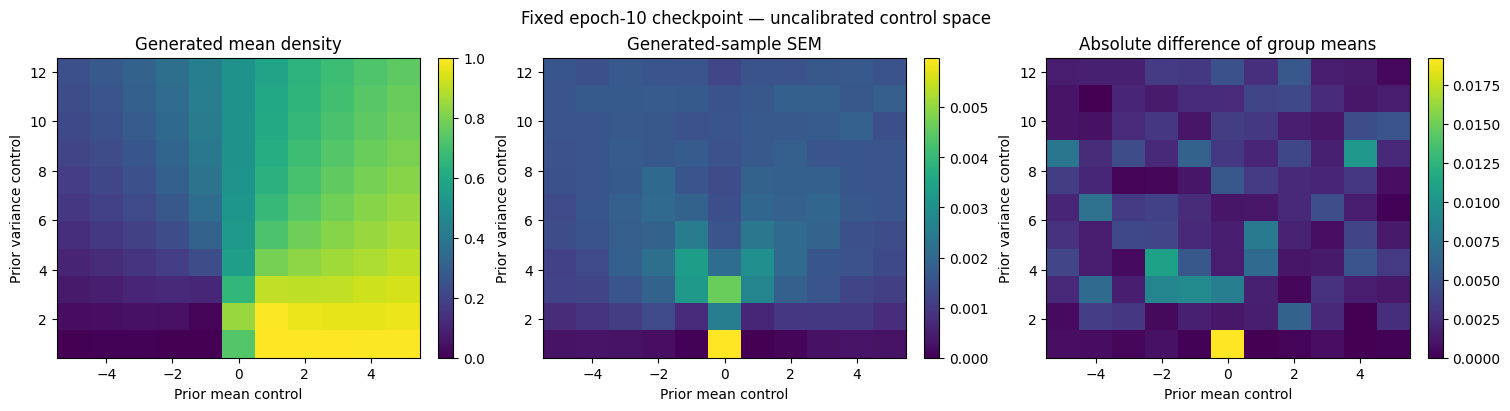

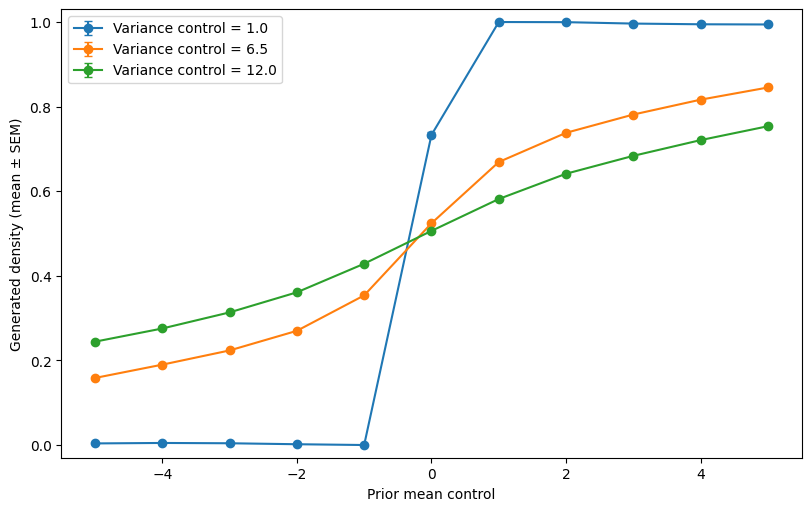

Review package: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\control_map_20261110T182511Z_33a169d2\control_map_review.zip
Preserve the entire run directory, including raw arrays. The compact ZIP omits raw arrays and weights.
Completed exploratory map; no calibrated physical axes or physical accuracy claim.


In [5]:
status = json.loads((RUN/"status.json").read_text())
assert status["status"] == "completed", "Finish or resume the grid before producing the final map."
rows = [summarize(point) for point in points]
write_json(RUN/"density_summary.json", rows)
with (RUN/"density_summary.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0])); writer.writeheader(); writer.writerows(rows)
mean_map = np.array([r["density_mean"] for r in rows]).reshape(11, 11)
sem_map = np.array([r["density_sem"] for r in rows]).reshape(11, 11)
group_gap_map = np.array([r["group_mean_abs_difference"] for r in rows]).reshape(11, 11)
np.savez(RUN/"density_arrays.npz", mean_controls=MEAN_VALUES, variance_controls=VARIANCE_VALUES,
    density_mean=mean_map, density_sem=sem_map, group_mean_abs_difference=group_gap_map)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, values, title, upper in zip(axes, [mean_map, sem_map, group_gap_map],
        ["Generated mean density", "Generated-sample SEM", "Absolute difference of group means"], [1, None, None]):
    im = ax.pcolormesh(MEAN_VALUES, VARIANCE_VALUES, values, shading="nearest", cmap="viridis", vmin=0, vmax=upper)
    ax.set_xlabel("Prior mean control"); ax.set_ylabel("Prior variance control")
    ax.set_title(title); fig.colorbar(im, ax=ax)
fig.suptitle("Fixed epoch-10 checkpoint — uncalibrated control space")
fig.savefig(RUN/"control_density_map.png", dpi=180); plt.show()
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
for i in [0, 5, 10]:
    ax.errorbar(MEAN_VALUES, mean_map[i], yerr=sem_map[i], marker="o", capsize=3,
                label=f"Variance control = {VARIANCE_VALUES[i]:.1f}")
ax.set(xlabel="Prior mean control", ylabel="Generated density (mean ± SEM)", ylim=(-.03, 1.03))
ax.legend(); fig.savefig(RUN/"density_slices.png", dpi=180); plt.show()
review_files = ["protocol.json", "status.json", "density_summary.json", "density_summary.csv",
                "density_arrays.npz", "control_density_map.png", "density_slices.png"]
with zipfile.ZipFile(RUN/"control_map_review.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for name in review_files: archive.write(RUN/name, name)
    for meta in sorted((RUN/"raw").glob("*.json")): archive.write(meta, "raw_metadata/"+meta.name)
print("Review package:", RUN/"control_map_review.zip")
print("Preserve the entire run directory, including raw arrays. The compact ZIP omits raw arrays and weights.")
print("Completed exploratory map; no calibrated physical axes or physical accuracy claim.")


Saved: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\control_map_20261110T182511Z_33a169d2\figure2_visual_comparison.png
Saved: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\control_map_20261110T182511Z_33a169d2\figure2_visual_comparison.pdf


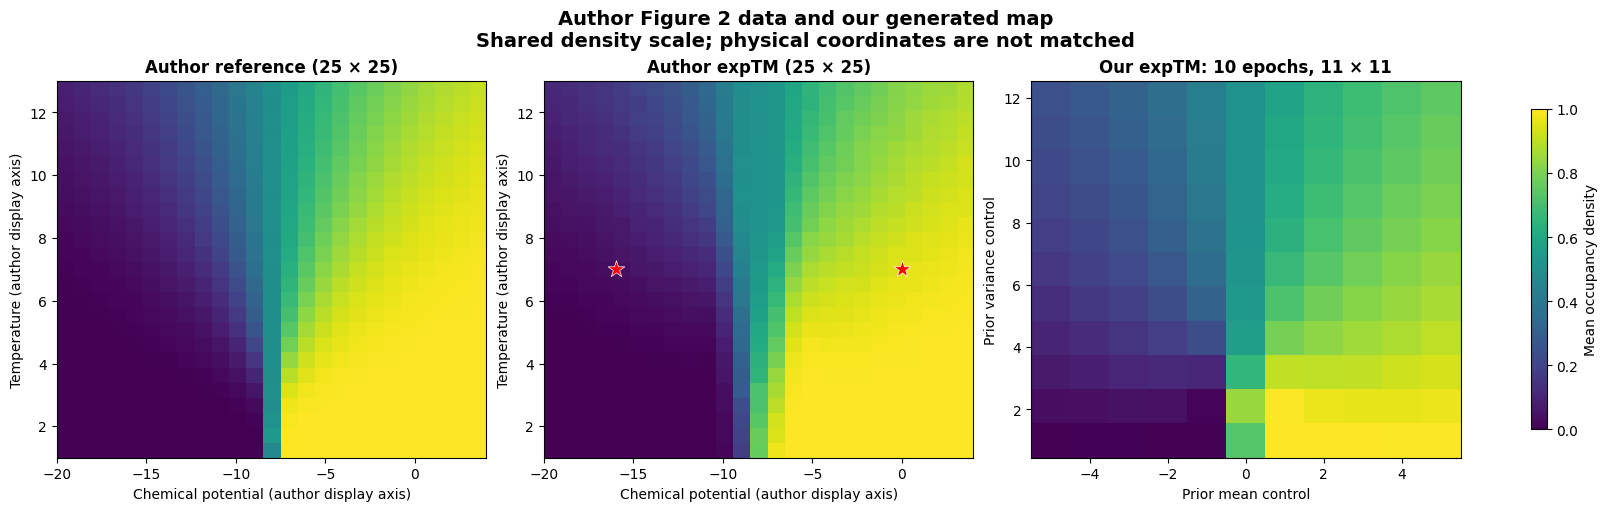

Author panels are replotted from the supplied manuscript arrays.
Visual comparison only: no coordinate fitting or pointwise error calculation.


In [6]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Reuse ROOT and RUN from the completed notebook.
assert "ROOT" in globals() and "RUN" in globals(), \
    "Keep the current notebook kernel, with ROOT and RUN defined."

figure_dir = (
    ROOT.parent / "ExpTM_Author_Followup" / "author_snapshot"
    / "GC_Lattice_gas" / "manuscript_figure"
)
assert figure_dir.is_dir(), f"Author figure folder not found: {figure_dir}"

reference = np.load(
    figure_dir / "org_density_matrix.npy", allow_pickle=False
)
author_generated = np.load(
    figure_dir / "density_matrix.npy", allow_pickle=False
)
assert reference.shape == (26, 26)
assert author_generated.shape == (25, 25)

# Follow the author's plotting notebook exactly for the reference crop.
reference = reference[:25, :25]

with np.load(RUN / "density_arrays.npz", allow_pickle=False) as result:
    our_density = result["density_mean"]
    mean_controls = result["mean_controls"]
    variance_controls = result["variance_controls"]

assert our_density.shape == (len(variance_controls), len(mean_controls))

fig, axes = plt.subplots(
    1, 3, figsize=(16, 5), constrained_layout=True
)

for ax, matrix, title in zip(
    axes[:2],
    [reference, author_generated],
    ["Author reference (25 × 25)", "Author expTM (25 × 25)"]
):
    im = ax.imshow(
        matrix, origin="lower", aspect="auto",
        extent=[-20, 4, 1, 13],
        interpolation="nearest",
        cmap="viridis", vmin=0, vmax=1
    )
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Chemical potential (author display axis)")
    ax.set_ylabel("Temperature (author display axis)")

axes[1].scatter(
    [-16, 0], [7, 7], marker="*", s=160,
    color="red", edgecolors="white", linewidths=0.5
)

axes[2].pcolormesh(
    mean_controls, variance_controls, our_density,
    shading="nearest", cmap="viridis", vmin=0, vmax=1
)
axes[2].set_title(
    "Our expTM: 10 epochs, 11 × 11",
    fontweight="bold"
)
axes[2].set_xlabel("Prior mean control")
axes[2].set_ylabel("Prior variance control")

fig.colorbar(
    im, ax=list(axes), shrink=0.85,
    label="Mean occupancy density"
)
fig.suptitle(
    "Author Figure 2 data and our generated map\n"
    "Shared density scale; physical coordinates are not matched",
    fontsize=14, fontweight="bold"
)

for extension in ["png", "pdf"]:
    path = RUN / f"figure2_visual_comparison.{extension}"
    fig.savefig(path, dpi=180, bbox_inches="tight")
    print("Saved:", path)

plt.show()

print("Author panels are replotted from the supplied manuscript arrays.")
print("Visual comparison only: no coordinate fitting or pointwise error calculation.")

In [ ]:
import sys
from importlib.metadata import version, PackageNotFoundError

print("Python:", sys.version)
print("Executable:", sys.executable)

for package in [
    "torch", "numpy", "scipy", "matplotlib",
    "einops", "tqdm", "pandas"
]:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: not installed")